In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
# ----------------- ÖZELLİKLERİ HAZIRLA -----------------
feature_names = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/feature_names.csv')['feature_name'].tolist()

# Aynı test.py'deki filtreleme
bad_indices = set()
for i, col_name in enumerate(feature_names):
    if 'pose_' in col_name:
        try:
            if int(col_name.split('_')[1]) >= 25:
                bad_indices.add(i)
        except: pass

valid_indices = [i for i in range(len(feature_names)) if i not in bad_indices]

# Burun merkezleme
idx_nose_x = feature_names.index('pose_0_x')
idx_nose_y = feature_names.index('pose_0_y')

feature_cols = [c for c in df.columns if c not in ['video_name', 'class_id', 'frame_no']]

X_list, y_list = [], []

for video, group in df.groupby('video_name'):
    raw = group[feature_cols].values  # (frame, 225)
    label = group['class_id'].iloc[0]

    norm_frames = []
    for row in raw:
        nx = row[idx_nose_x]
        ny = row[idx_nose_y]
        feat = []
        for i in valid_indices:
            val = row[i]
            if feature_names[i].endswith('_x'): val -= nx
            elif feature_names[i].endswith('_y'): val -= ny
            feat.append(val / 2.0)
        norm_frames.append(feat)

    frames = np.array(norm_frames)

    if len(frames) >= MAX_FRAMES:
        frames = frames[:MAX_FRAMES]
    else:
        pad = np.zeros((MAX_FRAMES - len(frames), len(valid_indices)))
        frames = np.vstack([frames, pad])

    X_list.append(frames)
    y_list.append(label)

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list)
print(f"X shape: {X.shape}")  # (2808, 100, 201) olmalı

X shape: (2808, 100, 201)


In [11]:
feature_cols = [c for c in df.columns if c not in ['video_name', 'class_id', 'frame_no']]

# Pose 25+ sütunlarını at
def is_bad(col):
    if 'pose_' in col:
        try:
            idx = int(col.split('_')[1])
            return idx >= 25
        except:
            return False
    return False

valid_cols = [c for c in feature_cols if not is_bad(c)]
print(f"Özellik sayısı: {len(valid_cols)}")  # 201 olmalı

idx_nose_x = valid_cols.index('pose_0_x')
idx_nose_y = valid_cols.index('pose_0_y')

X_list, y_list = [], []
MAX_FRAMES = 100

for video, group in df.groupby('video_name'):
    raw = group[valid_cols].values
    label = group['class_id'].iloc[0]

    norm_frames = []
    for row in raw:
        nx = row[idx_nose_x]
        ny = row[idx_nose_y]
        feat = []
        for i, col in enumerate(valid_cols):
            val = row[i]
            if col.endswith('_x'): val -= nx
            elif col.endswith('_y'): val -= ny
            feat.append(val / 2.0)
        norm_frames.append(feat)

    frames = np.array(norm_frames)
    if len(frames) >= MAX_FRAMES:
        frames = frames[:MAX_FRAMES]
    else:
        pad = np.zeros((MAX_FRAMES - len(frames), len(valid_cols)))
        frames = np.vstack([frames, pad])

    X_list.append(frames)
    y_list.append(label)

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list)
print(f"X shape: {X.shape}")  # (2808, 100, 201) olmalı

Özellik sayısı: 201
X shape: (2808, 100, 201)


In [12]:
# ----------------- MODELİ YÜKLE -----------------
model = keras.models.load_model('/content/drive/MyDrive/isaret_dili_beyni_FINAL.h5', compile=False)

# ----------------- TAHMİN -----------------
preds = model.predict(X, verbose=1)
y_pred = np.argmax(preds, axis=1)

# ----------------- RAPOR -----------------
from sklearn.metrics import classification_report
print(classification_report(y, y_pred))

# ----------------- EN KÖTÜ SINIFLAR -----------------
from sklearn.metrics import confusion_matrix
import seaborn as sns

report = classification_report(y, y_pred, output_dict=True)
per_class = {k: v['recall'] for k, v in report.items() if k.isdigit()}
sorted_classes = sorted(per_class.items(), key=lambda x: x[1])

print("\n❌ En kötü 10 sınıf:")
for cls, acc in sorted_classes[:10]:
    print(f"  Sınıf {cls}: %{acc*100:.1f}")

print("\n✅ En iyi 10 sınıf:")
for cls, acc in sorted_classes[-10:]:
    print(f"  Sınıf {cls}: %{acc*100:.1f}")

88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 136ms/step
              precision    recall  f1-score   support

           0       1.00      0.83      0.91        12
           1       0.64      0.75      0.69        12
           2       1.00      0.92      0.96        13
           3       1.00      0.92      0.96        12
           4       0.92      0.86      0.89        14
           5       0.92      0.92      0.92        13
           6       0.87      0.93      0.90        14
           7       0.77      0.77      0.77        13
           8       0.79      0.92      0.85        12
           9       0.86      0.86      0.86        14
          10       0.87      1.00      0.93        13
          11       1.00      1.00      1.00        11
          12       1.00      0.92      0.96        12
          13       0.75      0.69      0.72        13
          14       0.93      1.00      0.96        13
          15       0.77      0.91      0.83        11
          16       0.77      0.91      

88/88 ━━━━━━━━━━━━━━━━━━━━ 13s 147ms/step
Sınıf        Doğruluk   Bar
❌ Sınıf 116    % 30.8   ██████
❌ Sınıf 150    % 33.3   ██████
❌ Sınıf 221    % 33.3   ██████
❌ Sınıf 49     % 41.7   ████████
❌ Sınıf 68     % 41.7   ████████
❌ Sınıf 97     % 41.7   ████████
❌ Sınıf 111    % 41.7   ████████
❌ Sınıf 192    % 46.2   █████████
✅ Sınıf 52     % 50.0   ██████████
✅ Sınıf 53     % 50.0   ██████████
✅ Sınıf 71     % 50.0   ██████████
✅ Sınıf 78     % 50.0   ██████████
✅ Sınıf 175    % 50.0   ██████████
✅ Sınıf 144    % 53.8   ██████████
✅ Sınıf 147    % 53.8   ██████████
✅ Sınıf 148    % 54.5   ██████████
✅ Sınıf 106    % 57.1   ███████████
✅ Sınıf 212    % 57.1   ███████████
✅ Sınıf 187    % 58.3   ███████████
✅ Sınıf 225    % 58.3   ███████████
✅ Sınıf 38     % 61.5   ████████████
✅ Sınıf 48     % 61.5   ████████████
✅ Sınıf 140    % 61.5   ████████████
✅ Sınıf 142    % 61.5   ████████████
✅ Sınıf 146    % 61.5   ████████████
✅ Sınıf 155    % 61.5   ████████████
✅ Sınıf 215    % 61.5   █

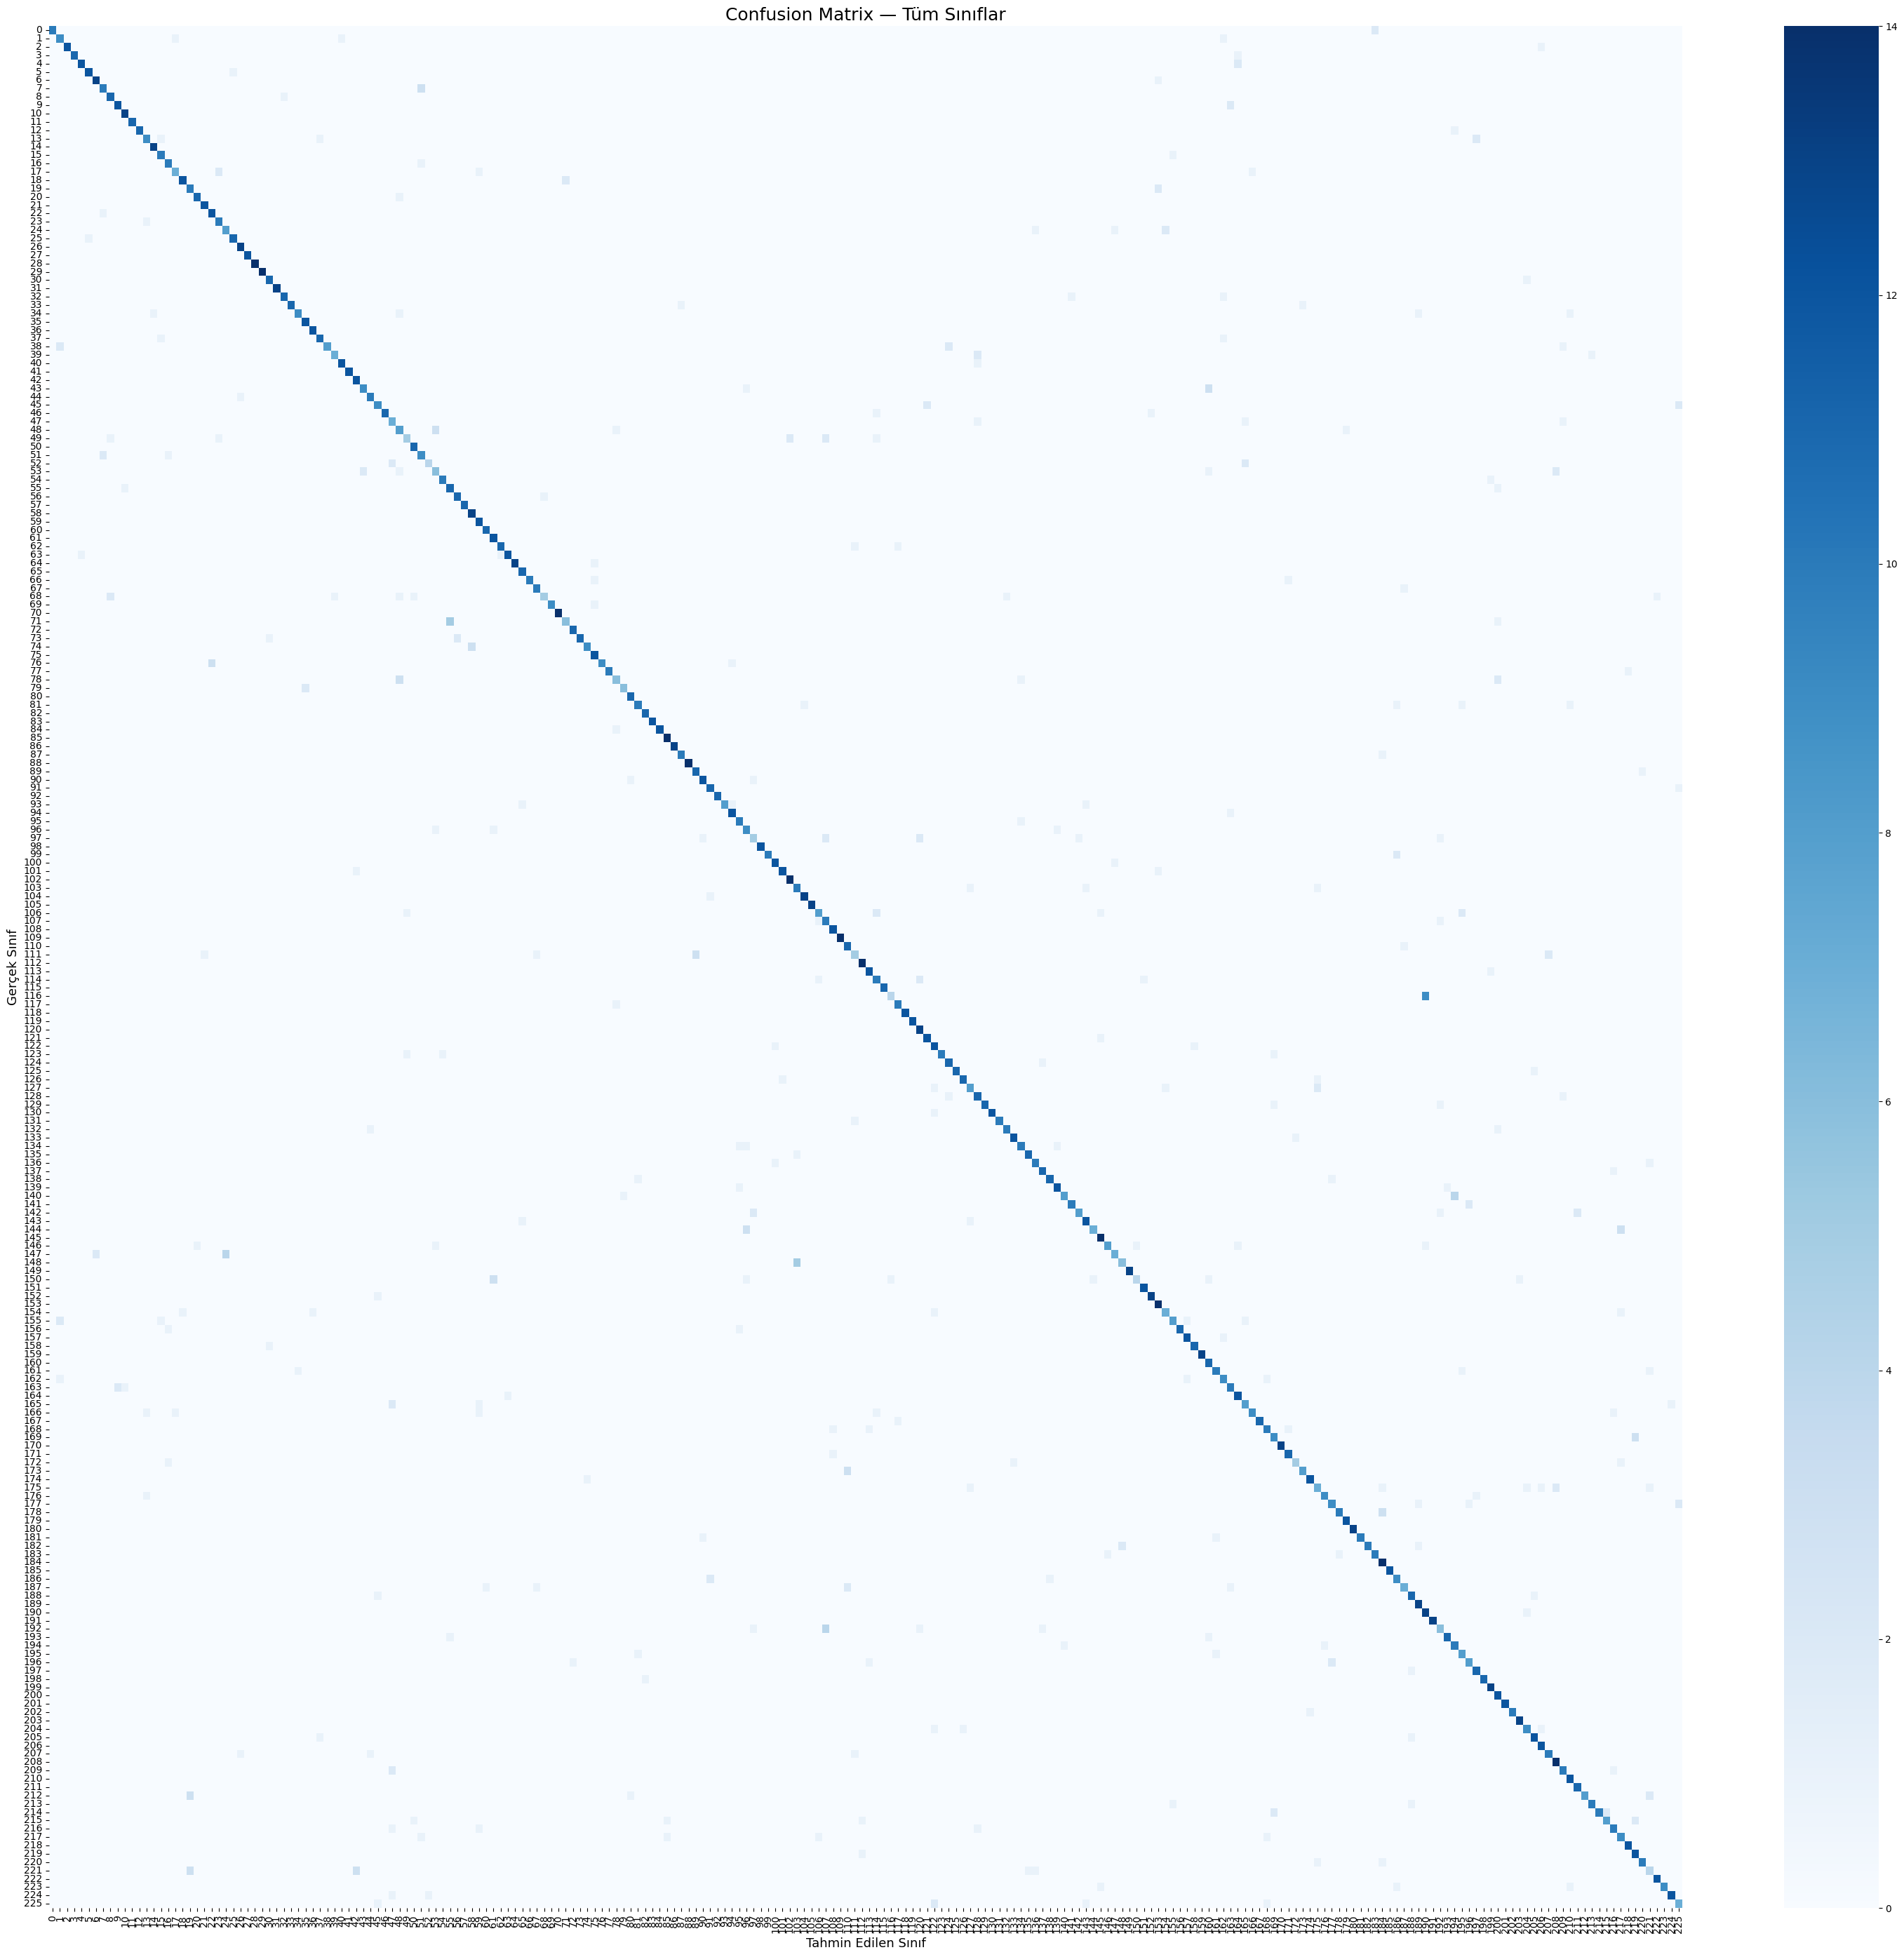

✅ confusion_matrix.png kaydedildi


In [13]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ----------------- TAHMİN -----------------
preds = model.predict(X, verbose=1)
y_pred = np.argmax(preds, axis=1)

# ----------------- TÜM SINIFLAR RAPORU -----------------
report = classification_report(y, y_pred, output_dict=True)
per_class = {int(k): v['recall'] for k, v in report.items() if k.isdigit()}
sorted_classes = sorted(per_class.items(), key=lambda x: x[1])

print("=" * 45)
print(f"{'Sınıf':<10} {'Doğruluk':>10}   {'Bar'}")
print("=" * 45)
for cls, acc in sorted_classes:
    bar = "█" * int(acc * 20)
    flag = "❌" if acc < 0.5 else "✅"
    print(f"{flag} Sınıf {cls:<6} %{acc*100:>5.1f}   {bar}")

print("=" * 45)
print(f"\n📊 Genel Accuracy: %{sum(y == y_pred)/len(y)*100:.1f}")

# ----------------- EN KÖTÜ 100 -----------------
print("\n\n❌ EN KÖTÜ 100 SINIF:")
print(f"{'Sınıf':<10} {'Doğruluk':>10}")
print("-" * 22)
for cls, acc in sorted_classes[:100]:
    print(f"  Sınıf {cls:<6} %{acc*100:>5.1f}")

# ----------------- EN İYİ 100 -----------------
print("\n\n✅ EN İYİ 100 SINIF:")
print(f"{'Sınıf':<10} {'Doğruluk':>10}")
print("-" * 22)
for cls, acc in sorted_classes[-100:]:
    print(f"  Sınıf {cls:<6} %{acc*100:>5.1f}")

# ----------------- CONFUSION MATRIX -----------------
cm = confusion_matrix(y, y_pred)
plt.figure(figsize=(30, 28))
sns.heatmap(
    cm,
    annot=False,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(np.unique(y)),
    yticklabels=sorted(np.unique(y))
)
plt.title('Confusion Matrix — Tüm Sınıflar', fontsize=18)
plt.ylabel('Gerçek Sınıf', fontsize=13)
plt.xlabel('Tahmin Edilen Sınıf', fontsize=13)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ confusion_matrix.png kaydedildi")

In [14]:
# Her sınıfta kaç video var?
from collections import Counter
class_counts = Counter(y)
print("En az örneği olan sınıflar:")
for cls, cnt in sorted(class_counts.items(), key=lambda x: x[1])[:20]:
    print(f"  Sınıf {cls}: {cnt} video")

print(f"\nOrtalama video/sınıf: {len(y)/len(class_counts):.1f}")
print(f"Min: {min(class_counts.values())}, Max: {max(class_counts.values())}")

En az örneği olan sınıflar:
  Sınıf 172: 8 video
  Sınıf 52: 8 video
  Sınıf 79: 8 video
  Sınıf 39: 10 video
  Sınıf 47: 10 video
  Sınıf 69: 10 video
  Sınıf 195: 10 video
  Sınıf 60: 11 video
  Sınıf 50: 11 video
  Sınıf 117: 11 video
  Sınıf 72: 11 video
  Sınıf 44: 11 video
  Sınıf 115: 11 video
  Sınıf 93: 11 video
  Sınıf 80: 11 video
  Sınıf 82: 11 video
  Sınıf 23: 11 video
  Sınıf 15: 11 video
  Sınıf 92: 11 video
  Sınıf 87: 11 video

Ortalama video/sınıf: 12.4
Min: 8, Max: 14


In [15]:
print("❌ EN KÖTÜ 100 SINIF (en düşükten yükseğe):")
print(f"{'Sıra':<6} {'Sınıf':<10} {'Doğruluk':>10}   {'Bar'}")
print("=" * 50)
for i, (cls, acc) in enumerate(sorted_classes[:100], 1):
    bar = "█" * int(acc * 20)
    print(f"{i:<6} Sınıf {cls:<6} %{acc*100:>5.1f}   {bar}")

❌ EN KÖTÜ 100 SINIF (en düşükten yükseğe):
Sıra   Sınıf        Doğruluk   Bar
1      Sınıf 116    % 30.8   ██████
2      Sınıf 150    % 33.3   ██████
3      Sınıf 221    % 33.3   ██████
4      Sınıf 49     % 41.7   ████████
5      Sınıf 68     % 41.7   ████████
6      Sınıf 97     % 41.7   ████████
7      Sınıf 111    % 41.7   ████████
8      Sınıf 192    % 46.2   █████████
9      Sınıf 52     % 50.0   ██████████
10     Sınıf 53     % 50.0   ██████████
11     Sınıf 71     % 50.0   ██████████
12     Sınıf 78     % 50.0   ██████████
13     Sınıf 175    % 50.0   ██████████
14     Sınıf 144    % 53.8   ██████████
15     Sınıf 147    % 53.8   ██████████
16     Sınıf 148    % 54.5   ██████████
17     Sınıf 106    % 57.1   ███████████
18     Sınıf 212    % 57.1   ███████████
19     Sınıf 187    % 58.3   ███████████
20     Sınıf 225    % 58.3   ███████████
21     Sınıf 38     % 61.5   ████████████
22     Sınıf 48     % 61.5   ████████████
23     Sınıf 140    % 61.5   ████████████
24     Sınıf 

In [6]:
# Sadece bu kodu çalıştır, başka bir şey yapma
with open('/content/drive/MyDrive/video_koordinat_verisetiTRAİN.csv' , 'r', encoding='utf-8') as f:
    header = f.readline().strip().split(',')

feature_names = header[3:]

# Kontrol edilecek indeksler
kontrol = [
    'pose_0_x',   # burun
    'pose_0_y',
    'pose_2_x',   # sağ göz
    'pose_2_y',
    'pose_5_x',   # sol göz
    'pose_5_y',
    'pose_9_x',   # ağız sağ
    'pose_9_y',
    'pose_10_x',  # ağız sol
    'pose_10_y',
    'pose_11_x',  # sağ omuz
    'pose_11_y',
    'pose_12_x',  # sol omuz
    'pose_12_y',
    'rh_0_x',     # sağ el bilek
    'rh_0_y',
    'lh_0_x',     # sol el bilek
    'lh_0_y',
]

print("Özellik adı → CSV'deki index")
print("-" * 35)
for name in kontrol:
    if name in feature_names:
        print(f"✅ {name:20s} → {feature_names.index(name)}")
    else:
        print(f"❌ {name:20s} → BULUNAMADI!")

Özellik adı → CSV'deki index
-----------------------------------
✅ pose_0_x             → 0
✅ pose_0_y             → 1
✅ pose_2_x             → 6
✅ pose_2_y             → 7
✅ pose_5_x             → 15
✅ pose_5_y             → 16
✅ pose_9_x             → 27
✅ pose_9_y             → 28
✅ pose_10_x            → 30
✅ pose_10_y            → 31
✅ pose_11_x            → 33
✅ pose_11_y            → 34
✅ pose_12_x            → 36
✅ pose_12_y            → 37
✅ rh_0_x               → 99
✅ rh_0_y               → 100
✅ lh_0_x               → 162
✅ lh_0_y               → 163
